# Video pairs classification — upload patterns
Pairs are classified and the similarity graphs built by `python -m scripts.classify_and_build_graphs` (run it first). This notebook loads its outputs for the sanity check and the visualisations.

In [17]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pickle
import pprint
import networkx as nx

import datetime as dt


#module_path = os.path.abspath(os.path.join(''))
#if module_path not in sys.path:
#    sys.path.append(module_path)

if os.path.isdir("../data/"):
    os.chdir("../")

from notebooks.plots_utils import *
from scripts.project_config import get_politician_abbr_name, get_politician2party
from scripts.classify_and_build_graphs import CLASSIFIED_DIR, NETWORKS_DIR, THRESHOLD_PATH

%load_ext autoreload
%autoreload 2

rcParams, column_width, page_width, shorts_style, RV_style = get_plt_attr()
plt.rcParams.update(rcParams)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Data Loading

## 1.1 Load channel metadata

In [18]:
nm_yt_channels = pd.read_json('data/youtube/channels/news_channels.json')
pp_yt_channels = pd.read_json('data/youtube/channels/pp_channels.json')
nm_tt_channels = pd.read_json('data/tiktok/channels/news_channels.json')
pp_tt_channels = pd.read_json('data/tiktok/channels/pp_channels.json')

## 1.2 Load transcripts and videos (YouTube & TikTok)

In [19]:
politician2party = get_politician2party()

In [20]:
yt_nm_videos_2022 = pd.read_json("data/youtube/videos/news_videos_2022.jsonl", lines=True)
yt_nm_videos_2024 = pd.read_json("data/youtube/videos/news_videos_2024.jsonl", lines=True)
yt_pp_videos_2022 = pd.read_json("data/youtube/videos/pp_videos_2022.jsonl", lines=True)
yt_pp_videos_2024 = pd.read_json("data/youtube/videos/pp_videos_2024.jsonl", lines=True)
for yt_df in [yt_nm_videos_2022, yt_nm_videos_2024, yt_pp_videos_2022, yt_pp_videos_2024]:
    yt_df['publishedAt'] = pd.to_datetime(yt_df['publishedAt']).dt.tz_localize(None)
    yt_df['party'] = yt_df['name_standard'].map(politician2party)

In [21]:
tt_nm_videos_2022 = pd.read_json("data/tiktok/videos/news_videos_2022.jsonl", lines=True)
tt_nm_videos_2024 = pd.read_json("data/tiktok/videos/news_videos_2024.jsonl", lines=True)
tt_pp_videos_2022 = pd.read_json("data/tiktok/videos/pp_videos_2022.jsonl", lines=True)
tt_pp_videos_2024 = pd.read_json("data/tiktok/videos/pp_videos_2024.jsonl", lines=True)
for tt_df in [tt_nm_videos_2022, tt_nm_videos_2024, tt_pp_videos_2022, tt_pp_videos_2024]:
    tt_df.rename(columns={'id':'videoId', 'voice_to_text':'transcript','create_time':'publishedAt'}, inplace=True)
    tt_df['videoId'] = tt_df['videoId'].apply(str)
    tt_df['publishedAt'] = pd.to_datetime(tt_df['publishedAt']).dt.tz_localize(None)
    tt_df['party'] = tt_df['name_standard'].map(politician2party)

In [22]:
yt_nm_standard_names = list(nm_yt_channels.name_standard)
yt_pp_standard_names = list(pp_yt_channels.name_standard)
tt_nm_standard_names = list(nm_tt_channels.name_standard)
tt_pp_standard_names = list(pp_tt_channels.name_standard)

## 1.4 Define politician ordering

In [23]:
politician_abbr_name = get_politician_abbr_name()

# Ordered list of actors (parties + politicians) for plots — stored as abbreviated names
order_full = [
    'LFI', 'Rima Hassan', 'Manon Aubry', 'Manuel Bompard', 'Mathilde Panot',
    'Jean-Luc Mélenchon', 'François Ruffin',
    'PCF', 'EELV', 'PS', 'PP',
    'RE', 'Emmanuel Macron', 'Gabriel Attal',
    'MoDem', 'UDI', 'UPR', 'LR',
    'François Asselineau',
    'Jordan Bardella', 'Marine Le Pen',
    'Florian Philippot', 'Éric Zemmour', 'Marion Maréchal',
]

# 2. Classification Sanity Check

Distribution of predicted probabilities across all pairs, with decision boundary τ.

In [24]:
with open(THRESHOLD_PATH) as f:
    best_thr = float(f.read())

sanity_check_files = [
    'pairs_yt_same_channel_pp_2024', 'pairs_yt_same_channel_nm_2024',
    'pairs_same_actor_yt_tt_pp_2024', 'pairs_same_party_yt_tt_2024', 'pairs_same_actor_yt_tt_nm_2024',
    'pairs_diff_channels_yt_pp_all_nm_2024', 'pairs_diff_channels_tt_pp_all_nm_2024',
]
predicted_probas = pd.concat([
    pd.read_csv(f'{CLASSIFIED_DIR}/{name}_classified.csv', usecols=['predicted_proba'])['predicted_proba']
    for name in sanity_check_files
]).tolist()

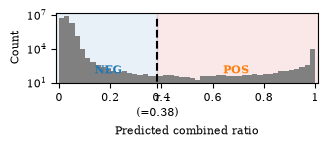

In [25]:
fig, ax = plt.subplots(figsize= (column_width, 1.5))

bin_edges = np.linspace(0, 1, 50)
# shaded region for predicted negative side
ax.axvspan(-0.01, best_thr, color="tab:blue", alpha=0.1)

# shaded region for predicted positive side
ax.axvspan(best_thr, 1.01, color="tab:red", alpha=0.1)
ax.hist(sorted(predicted_probas), bins = bin_edges, color = 'grey')

ax.plot([best_thr, best_thr], ax.get_ylim(), '--', color='k')

ax.set_xlabel('Predicted combined ratio')
ax.set_ylabel("Count")
ax.set_yscale('log')
ax.set_xlim(-0.01, 1.01)
ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1, best_thr], ['0', '0.2', '0.4', '0.6', '0.8', '1', r'$\tau$' + f'\n(={best_thr:.2f})'])
ax.set_xticklabels(ax.get_xticklabels())
ax.text(best_thr/2, 65, 'NEG', color='tab:blue', fontdict={'fontweight':'bold'}, ha='center')
ax.text(best_thr+(1-best_thr)/2, 65, 'POS', color='tab:orange', fontdict={'fontweight':'bold'}, ha='center')
plt.tight_layout()
#fig.savefig('figures_shortpaper_WWW/decision_boundary_plot.pdf')

# 3. Load Similarity Graphs

One graph per channel (or party): nodes are videos, edges connect pairs classified as matches.

In [26]:
def load_gs(filepath):
    filenames = [f for f in os.listdir(filepath) if f.endswith('.gv')]
    return {f.split('_')[0]: nx.nx_agraph.read_dot(filepath + f) for f in filenames}

gs_pp_only   = load_gs(f'{NETWORKS_DIR}/pp_only_2024/')
gs_news_only = load_gs(f'{NETWORKS_DIR}/news_only_2024/')
gs_diff      = load_gs(f'{NETWORKS_DIR}/diff_2024/')
gs_parties   = load_gs(f'{NETWORKS_DIR}/parties_2024/')

## 3.1 Helper: look up source video for a given video

In [27]:
# I do remember that for some cases I had to take it when it's larger than 1 but now it seems absurd to do so because when there is only one link it disappears
def get_source(row, name_standard, gs):
    try:
        videoId = row.videoId.values[0]
    except AttributeError as e:
        videoId = row.videoId
    if videoId in gs[name_standard]:
        #print(gs[name_standard][videoId])
        if len(list(gs[name_standard][videoId])) > 0:
            return list(gs[name_standard][videoId])
        else :
            return ''
    else: 
        return ''

# 5. Upload Pattern Visualisations

Timeline scatter plots showing when Regular Videos (RVs) and Shorts were posted, with lines connecting matched pairs.

## 5.1 Politician channels — within-channel matches (Shorts extracted from own RVs and TikTok posting)

In [28]:
politicians_yt_channelT = ['Jean-Luc Mélenchon', 'Mathilde Panot', 'Manon Aubry', 'Manuel Bompard', 'Rima Hassan',
                           'François Ruffin',
                           'Emmanuel Macron', 'Gabriel Attal',
                           'François Asselineau', 
                           'Nicolas Dupont-Aignan',
                           'Marine Le Pen', 'Jordan Bardella',
                           'Florian Philippot',
                           'Éric Zemmour', 'Marion Maréchal']

parties_yt_channelT = ['LO','NPA', 'LFI', 'PCF', 'EELV', 'PS', 'PP', 'UDI', 'RE', 'MoDem', 'LR', 'UPR', 'RN','LP',]

assert set(politicians_yt_channelT+parties_yt_channelT) == set(yt_pp_standard_names), \
f"set politicians and parties : {set(politicians_yt_channelT+parties_yt_channelT)}\nset yt_pp_standard names : {set(yt_pp_standard_names)}"


In [29]:
heads_of_party = ['Jean-Luc Mélenchon',
 'Emmanuel Macron',
 'Jordan Bardella']

In [30]:
def plot_upload_patterns(df_yt_all, df_tt_all, gs, channels_list = None, save_fig = None, parties_all_members = False):
    
    if not channels_list:
        channels_list = list(df_yt_all.name_standard.unique())
    
    fig, axes = plt.subplots(len(channels_list), 1, 
                         figsize=(column_width, len(channels_list)*0.75), sharex=True)
    
    x0 = None
    y_position_RVs = 0.1
    y_position_Shorts_bot = 0.89
    y_position_Shorts_top = 1.1
    y_position_TikTok = 1.9
    
    for i, name_standard in enumerate(channels_list):
        ax = axes[i]
        
        if parties_all_members: filter_col = 'party'
        else: filter_col = 'name_standard'
            
        df_yt = df_yt_all[df_yt_all[filter_col] == name_standard]
        
        df_yt['type'] = df_yt['isShort'].apply(lambda x: 'S' if x else 'RV')
        df_yt['publishedAt'] = df_yt['publishedAt'].dt.tz_localize(None)
        
        df_yt_w_tr = df_yt[~(df_yt.transcript.isna()) & (df_yt.transcript != '') ]
        df_yt_wo_tr = df_yt[(df_yt.transcript.isna()) | (df_yt.transcript == '')]
        
        df_yt_w_tr.loc[df_yt_w_tr.type == 'S', 'source_videoId_yt'] = df_yt_w_tr.loc[df_yt_w_tr.type == 'S'].apply(
            get_source, name_standard=name_standard, gs=gs, axis=1)
        
        
        df_tt = df_tt_all[df_tt_all[filter_col] == name_standard][['videoId', 'publishedAt']]
            
        df_tt['source_videoId_tt'] = df_tt.apply(
            get_source, name_standard=name_standard, gs=gs, axis=1, result_type='reduce')
        
        df_tt['type'] = 'TT'
        df_tt['publishedAt'] = df_tt['publishedAt'].dt.tz_localize(None)
        
        df = pd.concat([df_yt_w_tr, df_tt])
        
        s = 10
        for video_type in ['RV', 'S', 'TT']:
            ax.scatter(
                x=df[df['type'] == video_type]['publishedAt'],
                y=df[df['type'] == video_type]['type'],
                s=s, edgecolors='k', linewidth=0.5
            )
            # if no Rv, no Short, or no TikTok, put an invisible point so that the label appear on the figure at the right position
            if len(df[df['type'] == video_type]) == 0:
                
                ax.scatter(
                x=dt.datetime.strptime('2024-05-15 19:05:00',
                     '%Y-%m-%d %H:%M:%S'),
                y=video_type,
                s=s, edgecolors='w', color = 'w', linewidth=0.5
            )
                
        for video_type in ['RV', 'S']:
            ax.scatter(
                x=df_yt_wo_tr[df_yt_wo_tr['type'] == video_type]['publishedAt'],
                y=df_yt_wo_tr[df_yt_wo_tr['type'] == video_type]['type'],
                s=s, edgecolors='grey', color='lightgrey', linewidth=0.5
            )
        
        # Lines: video match between short and RV
        for _, row in df_yt_w_tr.dropna(subset=['source_videoId_yt']).iterrows():
            for source_video in row['source_videoId_yt']:
                src_time = df_yt_w_tr.loc[df_yt_w_tr['videoId'] == source_video, 'publishedAt'].values
                if len(src_time):
                    ax.plot([src_time[0], row['publishedAt']], 
                            [y_position_RVs, y_position_Shorts_bot], color='k', linewidth=0.4)
        
        # Lines: video match between youtube and tiktok
        for _, row in df_tt.dropna(subset=['source_videoId_tt']).iterrows():
            source_videos = row['source_videoId_tt']
            
            # Check if there's a Short among the sources
            short_sources = [sv for sv in source_videos 
                             if sv in df_yt_w_tr['videoId'].values 
                             and df_yt_w_tr.loc[df_yt_w_tr['videoId'] == sv, 'type'].values[0] == 'S']
            
            # Collect RVs that are already linked to one of those Shorts (via source_videoId_yt)
            rvs_covered_by_shorts = set()
            for short_id in short_sources:
                short_row = df_yt_w_tr.loc[df_yt_w_tr['videoId'] == short_id]
                if len(short_row) and len(short_row.iloc[0].get('source_videoId_yt')) > 0:
                    for rv in short_row.iloc[0]['source_videoId_yt']:
                        rvs_covered_by_shorts.add(rv)
            
            for source_video in source_videos:
                yt_video_row = df_yt_w_tr.loc[df_yt_w_tr['videoId'] == source_video]
                if len(yt_video_row):
                    source_video_type = yt_video_row['type'].values[0]
                    source_time = yt_video_row['publishedAt'].values[0]
                    if source_video_type == 'RV':
                        # Skip this RV→TikTok line if the RV is already covered via a Short
                        if source_video in rvs_covered_by_shorts:
                            continue
                        ax.plot([source_time, row['publishedAt']], 
                                [y_position_RVs, y_position_TikTok], color='b', linewidth=0.4)
                    elif source_video_type == 'S':
                        ax.plot([source_time, row['publishedAt']], 
                                [y_position_Shorts_top, y_position_TikTok], color='b', linewidth=0.4)
                    else:
                        raise ValueError(yt_video_row['type'])
    
    
        ax.set_ylim(-0.5, 3.2)
        ax.set_xticks(['2024-03-01', '2024-03-15', '2024-04-01', '2024-04-15', '2024-05-01',
                       '2024-05-15', '2024-06-01', '2024-06-15', '2024-07-01', '2024-07-15'])
        ax.set_xticklabels(['1-03', '15-03', '1-04', '15-04', '1-05',
                            '15-05', '1-06', '15-06', '1-07', '15-07'],
                           rotation=45, ha='right', rotation_mode='anchor')
        if x0 is None:
            x0, _ = ax.get_xlim()
        ax.text(x0 + 2, 2.5, name_standard)
        
        
        #ax.set_ylim(-0.5, 1.5)
    plt.tight_layout(pad=1.5, w_pad=0, h_pad=0)
    if save_fig:
        plt.savefig(save_fig, bbox_inches='tight')

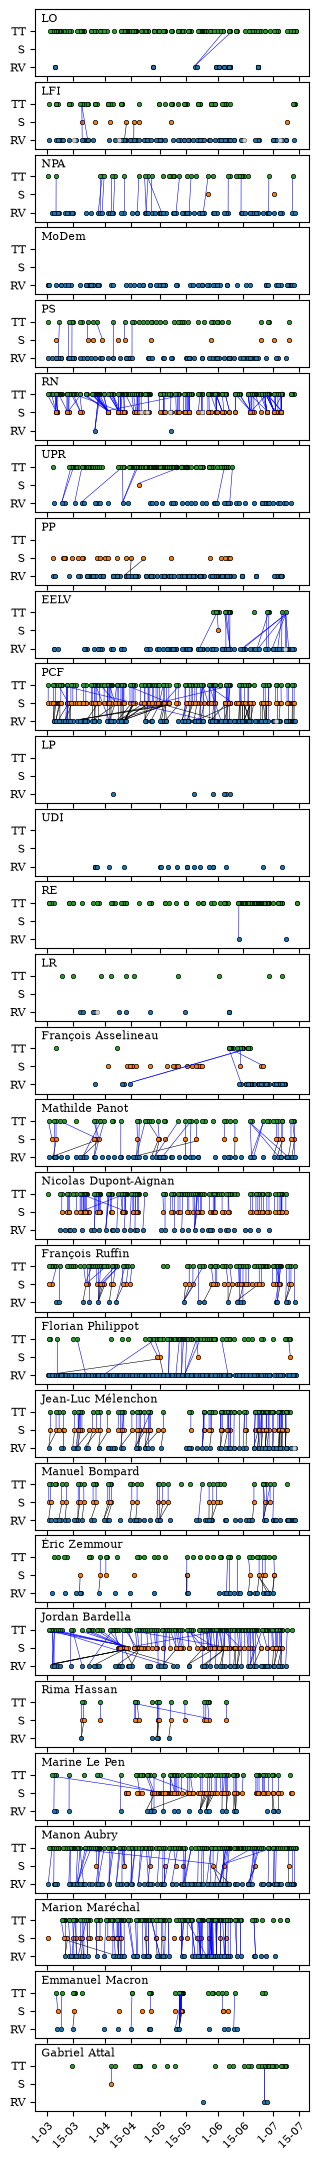

In [31]:
plot_upload_patterns(df_yt_all = yt_pp_videos_2024, df_tt_all = tt_pp_videos_2024, gs = gs_pp_only, 
                     save_fig = f'Figures/upload_patterns_pp.pdf')

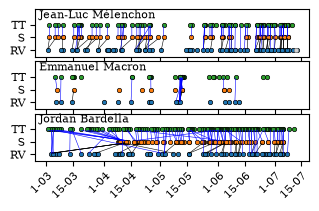

In [32]:
plot_upload_patterns(df_yt_all = yt_pp_videos_2024, df_tt_all = tt_pp_videos_2024, gs = gs_pp_only, 
                     channels_list = heads_of_party, save_fig = f'Figures/upload_patterns_heads_parties.pdf')

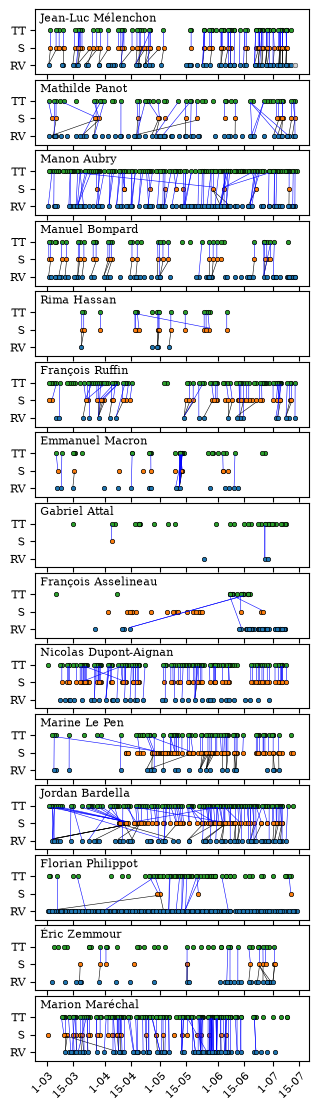

In [33]:
plot_upload_patterns(df_yt_all = yt_pp_videos_2024, df_tt_all = tt_pp_videos_2024, gs = gs_pp_only, 
                     channels_list = politicians_yt_channelT, save_fig = f'Figures/upload_patterns_polit.pdf')

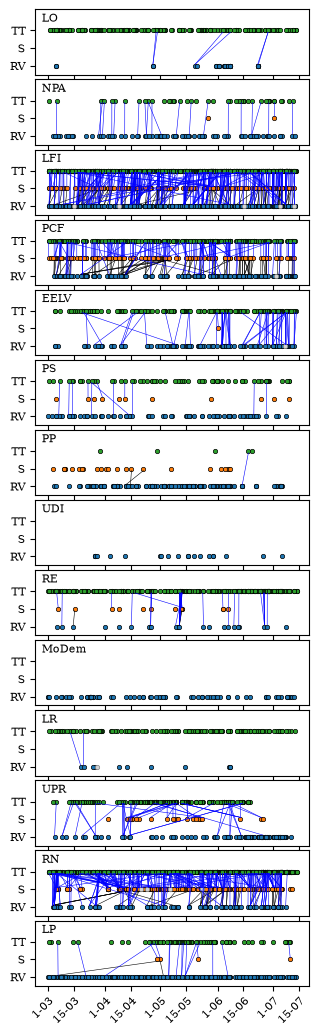

In [34]:
plot_upload_patterns(df_yt_all = yt_pp_videos_2024, df_tt_all = tt_pp_videos_2024, gs = gs_parties, 
                     channels_list = parties_yt_channelT, save_fig = f'Figures/upload_patterns_parties.pdf', parties_all_members = True)

## 6.2 News channels — within-channel matches (Shorts extracted from own RVs)

/var/folders/s8/86mtzm812zdfvh1cgg7lh2wh0000gp/T/ipykernel_38112/1003628801.py:122: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(pad=1.5, w_pad=0, h_pad=0)


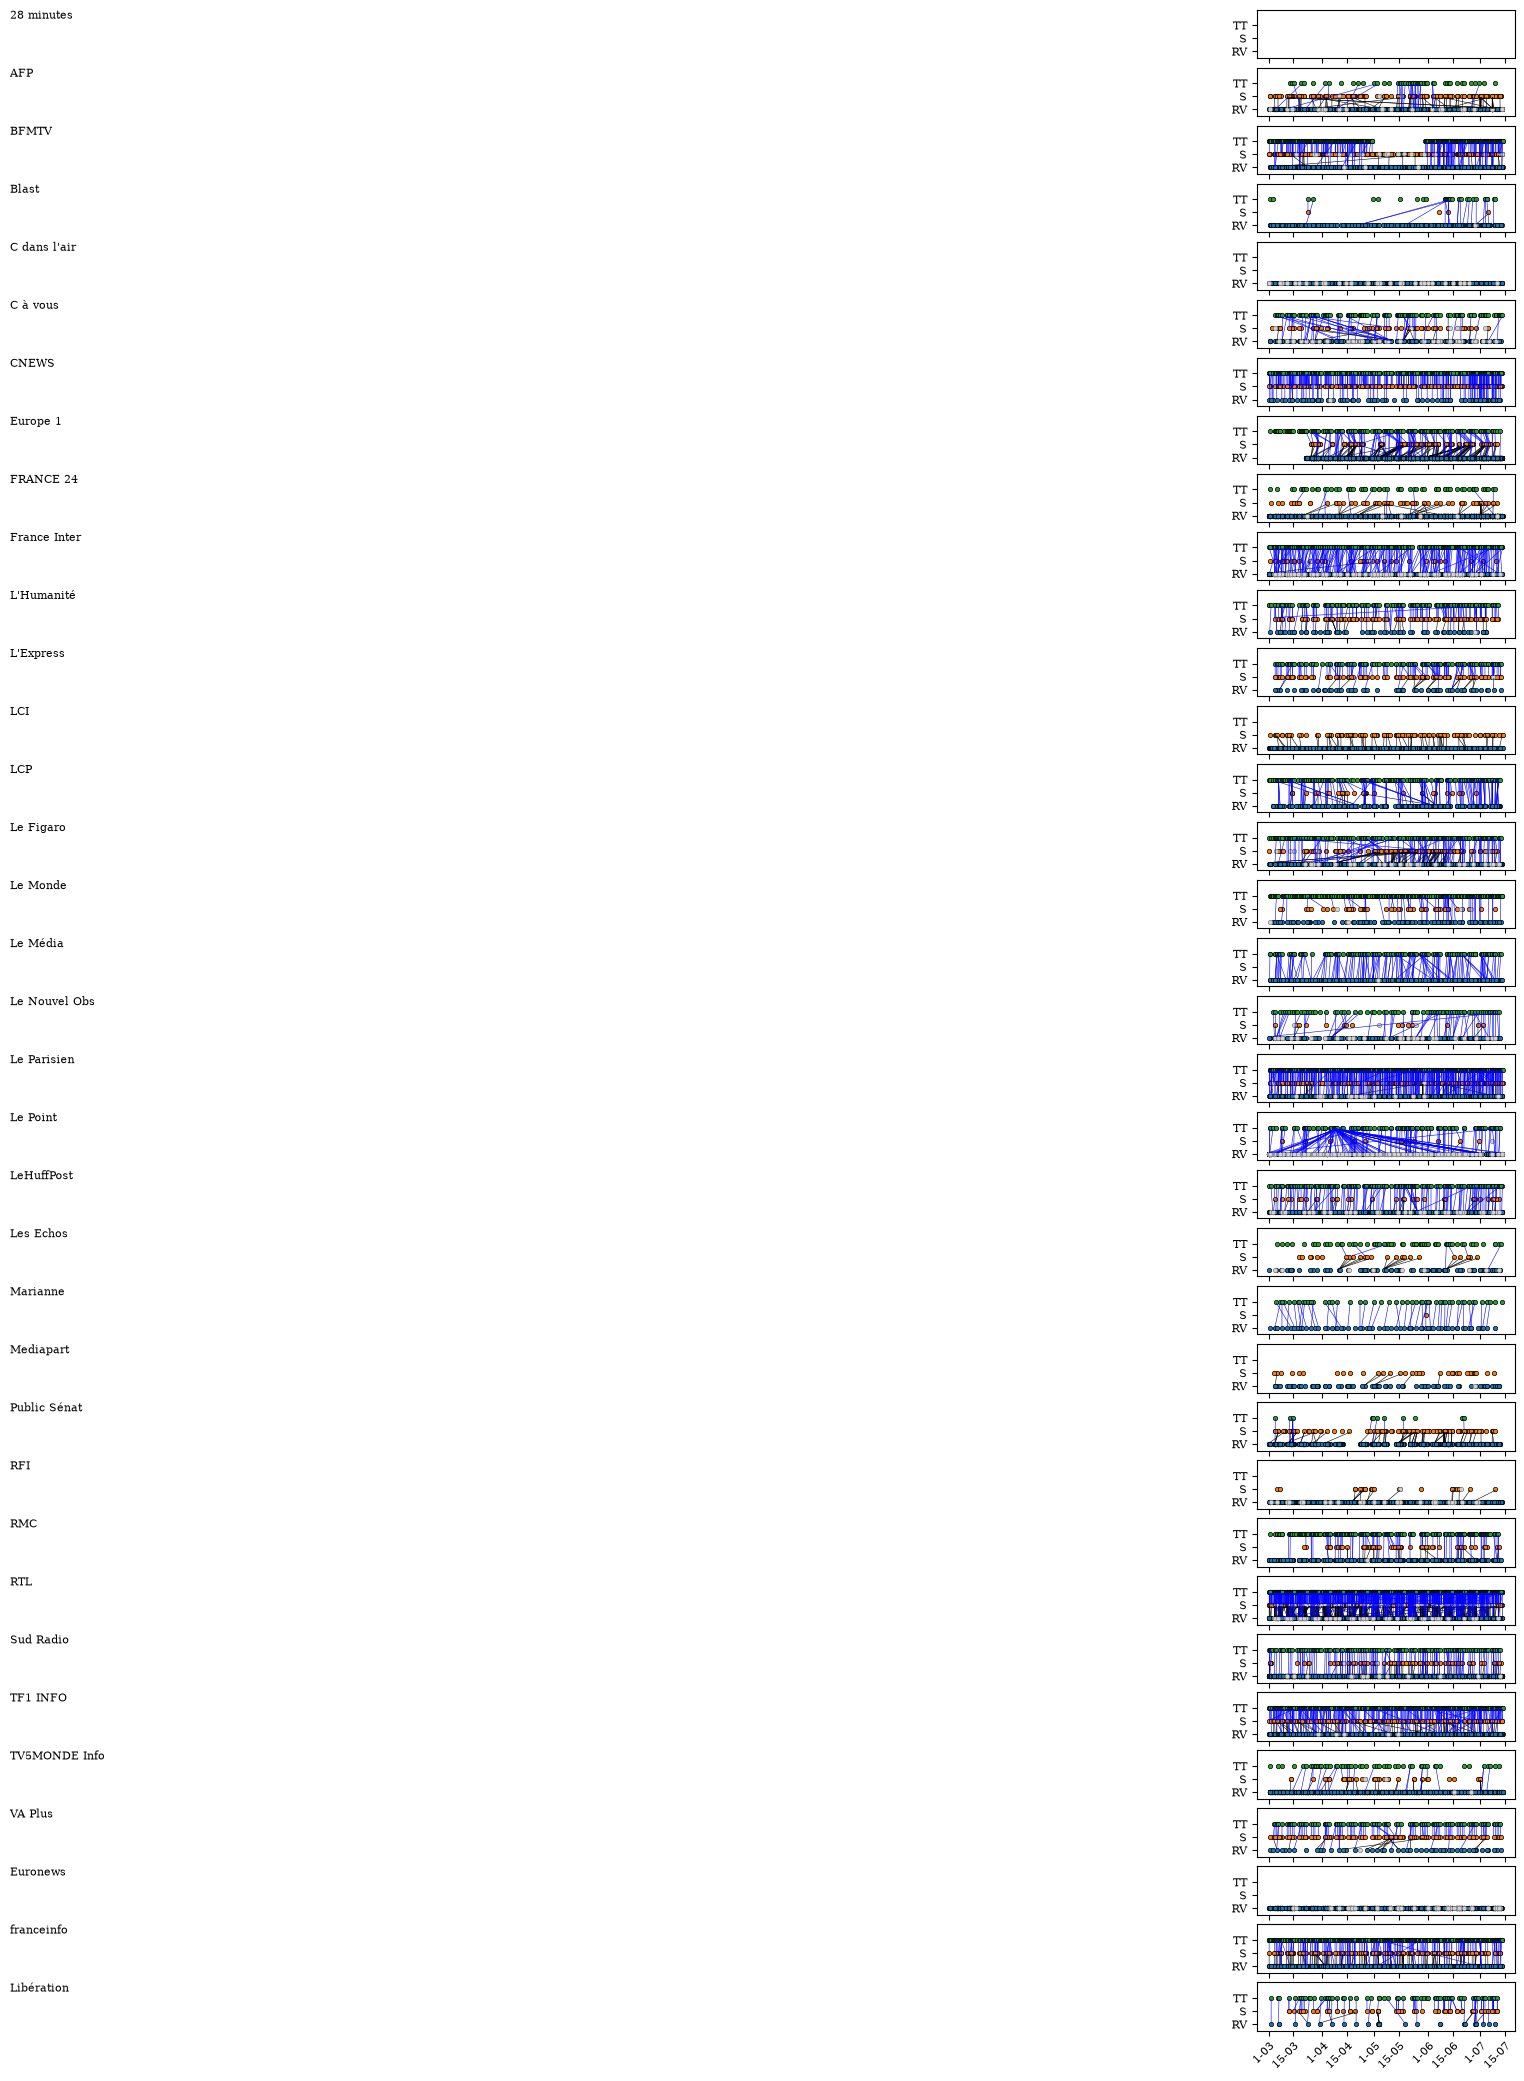

In [35]:
plot_upload_patterns(df_yt_all = yt_nm_videos_2024, df_tt_all = tt_nm_videos_2024, gs = gs_news_only, 
                     channels_list = yt_nm_standard_names, save_fig = f'Figures/upload_patterns_nm.pdf')

## 6.3 cross-channel matches (politician vs. news)

In [36]:
def plot_upload_patterns_news_pp(df_yt_all, df_tt_all, gs, df_news_all, gs_news=None, channels_list=None,
                         save_fig=None, parties_all_members=False,
                         news_flag_col=None):

    if gs_news is None:
        gs_news = gs  # fall back to single graph if no separate news graph given

    if not channels_list:
        channels_list = list(df_yt_all.name_standard.unique())

    fig, axes = plt.subplots(len(channels_list), 1,
                             figsize=(column_width, len(channels_list)), sharex=True)

    x0 = None

    y_position_News = 0.1
    y_position_RVs_bot = 0.89
    y_position_RVs_top = 1.1
    y_position_Shorts_bot = 1.89
    y_position_Shorts_top = 2.1
    y_position_TikTok = 2.9

    for i, name_standard in enumerate(channels_list):
        ax = axes[i]

        if parties_all_members:
            filter_col = 'party'
        else:
            filter_col = 'name_standard'

        df_yt = df_yt_all[df_yt_all[filter_col] == name_standard]

        df_yt['type'] = df_yt['isShort'].apply(lambda x: 'S' if x else 'RV')
        df_yt['publishedAt'] = df_yt['publishedAt'].dt.tz_localize(None)

        df_yt_w_tr = df_yt[~(df_yt.transcript.isna()) & (df_yt.transcript != '')]
        df_yt_wo_tr = df_yt[(df_yt.transcript.isna()) | (df_yt.transcript == '')]

        df_yt_w_tr.loc[df_yt_w_tr.type == 'S', 'source_videoId_yt'] = df_yt_w_tr.loc[df_yt_w_tr.type == 'S'].apply(
            get_source, name_standard=name_standard, gs=gs, axis=1)
        
            # --- News videos mentioning this channel (from df_yt_all via boolean column) ---
        if name_standard in df_news_all.columns:
            df_news = df_news_all[
                (df_news_all[name_standard] == True) &
                (~(df_news_all.transcript.isna()) & (df_news_all.transcript != ''))
            ][['videoId', 'isShort', 'publishedAt', 'transcript']].copy()
        else:
            # no news column for this channel -> empty frame with expected cols
            df_news = df_news_all.iloc[0:0][['videoId', 'isShort', 'publishedAt', 'transcript']].copy()

        df_news['type'] = 'News'
        if len(df_news):
            df_news['publishedAt'] = df_news['publishedAt'].dt.tz_localize(None)

        # For each politician video with transcript, find its news source(s) (list-valued)
        df_yt_w_tr['source_videoId_news'] = df_yt_w_tr.apply(
            get_source, name_standard=name_standard, gs=gs_news, axis=1)

        # --- TikTok ---
        df_tt = df_tt_all[df_tt_all[filter_col] == name_standard][['videoId', 'publishedAt']]

        df_tt['source_videoId_tt'] = df_tt.apply(
            get_source, name_standard=name_standard, gs=gs, axis=1, result_type='reduce')

        df_tt['type'] = 'TT'
        df_tt['publishedAt'] = df_tt['publishedAt'].dt.tz_localize(None)

        df = pd.concat([df_yt_w_tr, df_tt, df_news])

        s = 10
        for video_type in ['News', 'RV', 'S', 'TT']:
            ax.scatter(
                x=df[df['type'] == video_type]['publishedAt'],
                y=df[df['type'] == video_type]['type'],
                s=s, edgecolors='k', linewidth=0.5
            )
            # invisible anchor so the label appears at the right position when a row is empty
            if len(df[df['type'] == video_type]) == 0:
                ax.scatter(
                    x=dt.datetime.strptime('2024-05-15 19:05:00', '%Y-%m-%d %H:%M:%S'),
                    y=video_type,
                    s=s, edgecolors='w', color='w', linewidth=0.5
                )

        for video_type in ['RV', 'S']:
            ax.scatter(
                x=df_yt_wo_tr[df_yt_wo_tr['type'] == video_type]['publishedAt'],
                y=df_yt_wo_tr[df_yt_wo_tr['type'] == video_type]['type'],
                s=s, edgecolors='grey', color='lightgrey', linewidth=0.5
            )

        # Lines: video match between short and RV (own YouTube reuse)
        for _, row in df_yt_w_tr.dropna(subset=['source_videoId_yt']).iterrows():
            for source_video in row['source_videoId_yt']:
                src_time = df_yt_w_tr.loc[df_yt_w_tr['videoId'] == source_video, 'publishedAt'].values
                if len(src_time):
                    ax.plot([src_time[0], row['publishedAt']],
                            [y_position_RVs_top, y_position_Shorts_bot], color='k', linewidth=0.4)

        # Lines: news video -> politician RV/Short (cross-source news reuse)
        for _, row in df_yt_w_tr.dropna(subset=['source_videoId_news']).iterrows():
            for source_video in row['source_videoId_news']:
                src_time = df_news.loc[df_news['videoId'] == source_video, 'publishedAt'].values
                if len(src_time):
                    # top anchor on the politician side depends on whether it's an RV or a Short
                    y_polit = y_position_Shorts_bot if row['type'] == 'S' else y_position_RVs_bot
                    ax.plot([src_time[0], row['publishedAt']],
                            [y_position_News, y_polit], color='g', linewidth=0.4)

        # Lines: video match between youtube and tiktok
        for _, row in df_tt.dropna(subset=['source_videoId_tt']).iterrows():
            source_videos = row['source_videoId_tt']

            # Check if there's a Short among the sources
            short_sources = [sv for sv in source_videos
                             if sv in df_yt_w_tr['videoId'].values
                             and df_yt_w_tr.loc[df_yt_w_tr['videoId'] == sv, 'type'].values[0] == 'S']

            # Collect RVs already linked to one of those Shorts (via source_videoId_yt)
            rvs_covered_by_shorts = set()
            for short_id in short_sources:
                short_row = df_yt_w_tr.loc[df_yt_w_tr['videoId'] == short_id]
                if len(short_row) and len(short_row.iloc[0].get('source_videoId_yt')) > 0:
                    for rv in short_row.iloc[0]['source_videoId_yt']:
                        rvs_covered_by_shorts.add(rv)

            for source_video in source_videos:
                yt_video_row = df_yt_w_tr.loc[df_yt_w_tr['videoId'] == source_video]
                if len(yt_video_row):
                    source_video_type = yt_video_row['type'].values[0]
                    source_time = yt_video_row['publishedAt'].values[0]
                    if source_video_type == 'RV':
                        if source_video in rvs_covered_by_shorts:
                            continue
                        ax.plot([source_time, row['publishedAt']],
                                [y_position_RVs_top, y_position_TikTok], color='b', linewidth=0.4)
                    elif source_video_type == 'S':
                        ax.plot([source_time, row['publishedAt']],
                                [y_position_Shorts_top, y_position_TikTok], color='b', linewidth=0.4)
                    else:
                        raise ValueError(yt_video_row['type'])

        ax.set_ylim(-0.5, 4)
        ax.set_xticks(['2024-03-01', '2024-03-15', '2024-04-01', '2024-04-15', '2024-05-01',
                       '2024-05-15', '2024-06-01', '2024-06-15', '2024-07-01', '2024-07-15'])
        ax.set_xticklabels(['1-03', '15-03', '1-04', '15-04', '1-05',
                            '15-05', '1-06', '15-06', '1-07', '15-07'],
                           rotation=45, ha='right', rotation_mode='anchor')
        if x0 is None:
            x0, _ = ax.get_xlim()
        ax.text(x0 + 2, 3.2, name_standard)

    leg = [
        Line2D((1, 1), (1, 1), color='k', label='own YouTube match (RV↔Short)'),
        Line2D((1, 1), (1, 1), color='b', label='YouTube↔TikTok match'),
        Line2D((1, 1), (1, 1), color='g', label='news videos match'),
    ]
    fig.legend(handles=leg, loc=(0.15, 0.905), ncol=3)

    plt.tight_layout(pad=1.5, w_pad=0, h_pad=0)
    if save_fig:
        plt.savefig(save_fig, bbox_inches='tight')

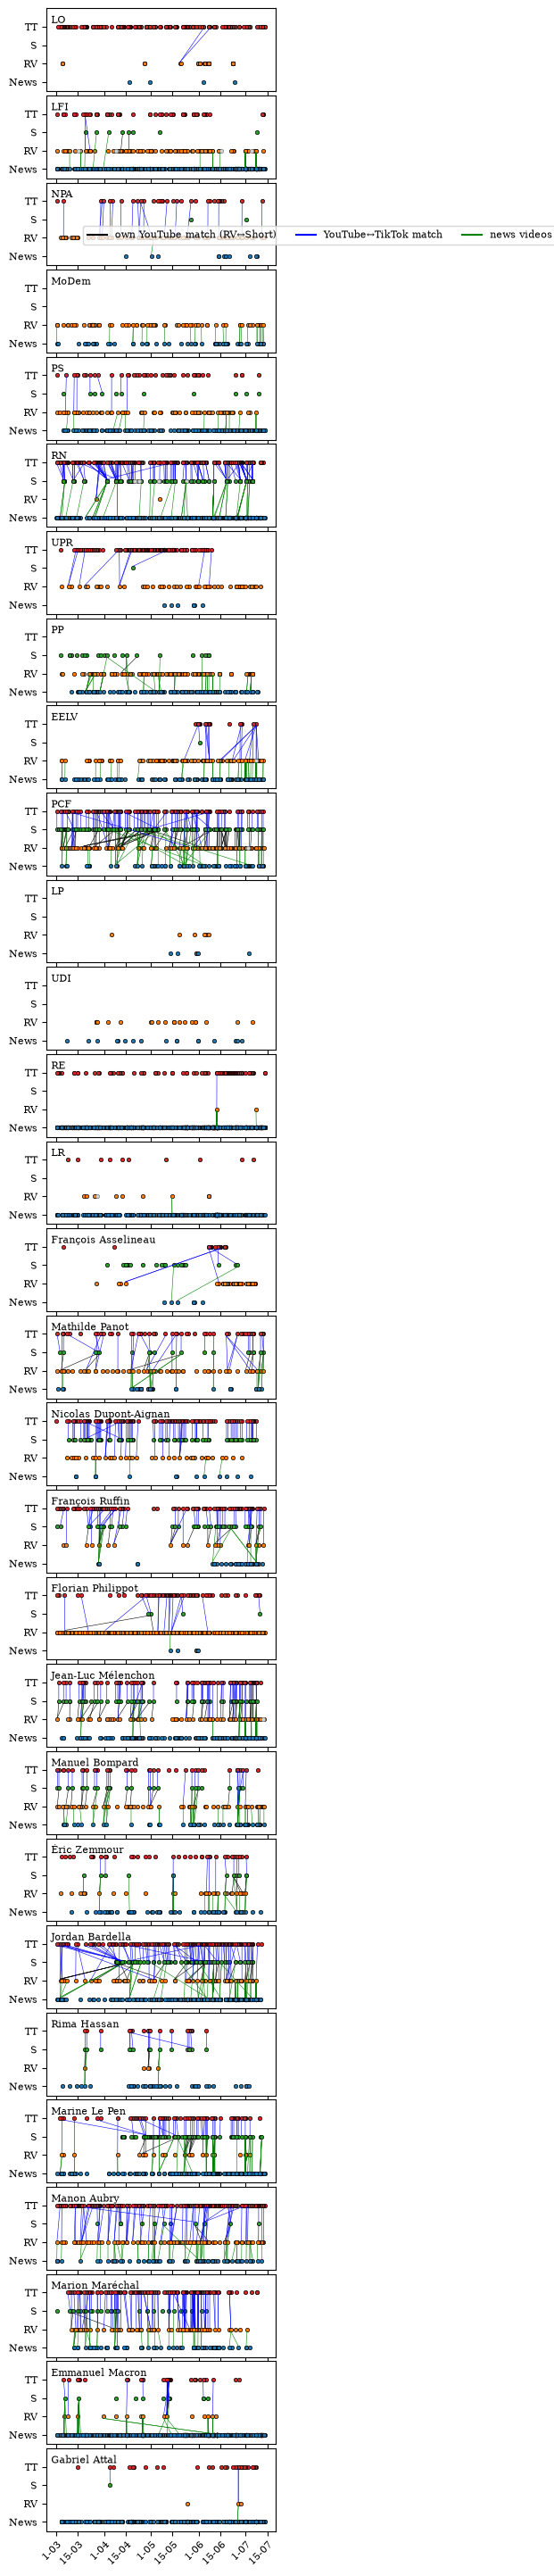

In [37]:
plot_upload_patterns_news_pp(df_yt_all = yt_pp_videos_2024, df_tt_all = tt_pp_videos_2024,
                             df_news_all=yt_nm_videos_2024,
                             gs = gs_pp_only, gs_news=gs_diff, channels_list=None,
                             save_fig=None, parties_all_members=False,
                             news_flag_col=None)